# CodeAlpha — Task 3: Handwritten Character Recognition (MNIST)

**Model:** CNN (TensorFlow/Keras)  
**Dataset:** MNIST in CSV format from Kaggle  
**Goal:** Classify handwritten digits (0–9).

### Before running
1. In Google Colab, select **Runtime → Change runtime type → T4 GPU** (if available).
2. Run the cells from top to bottom.
3. Paste your Kaggle API token into the clearly marked placeholder in the authentication cell. Never publish a notebook containing your real token.

The notebook downloads the dataset through the Kaggle API, preprocesses it, trains a compact CNN, evaluates it on the held-out test set, and saves the trained model and evaluation outputs.


## 1. Install and import libraries

In [1]:
!pip -q install -U kaggle

import os
import json
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print("TensorFlow:", tf.__version__)
print("Available GPU(s):", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
Available GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configure reproducibility and GPU

In [3]:
SEED = 42
BATCH_SIZE = 256
EPOCHS = 12
IMG_SIZE = 28
NUM_CLASSES = 10
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    # Mixed precision can speed up supported NVIDIA GPUs.
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
    print("GPU detected. Mixed precision enabled.")
else:
    tf.keras.mixed_precision.set_global_policy("float32")
    print("No GPU detected. Running with CPU / float32.")

print("Compute policy:", tf.keras.mixed_precision.global_policy())


GPU detected. Mixed precision enabled.
Compute policy: <DTypePolicy "mixed_float16">


## 3. Connect Kaggle API using the new token (no `kaggle.json` needed)

1. Open Kaggle → Settings → API → **Generate New Token**.
2. Copy the token string.
3. Paste it into the placeholder in the next code cell.
4. Run the cell, then run the dataset-download cell below.

This uses Kaggle CLI's supported `KAGGLE_API_TOKEN` environment variable / access-token authentication. **Do not upload a notebook containing your real token to GitHub.** Before publishing, replace the token with the placeholder again or remove the credential cell.

In [4]:
# Paste your Kaggle API token between the quotes below.
# Example format: "KGAT_..." (use YOUR newly generated token)
KAGGLE_API_TOKEN = "PASTE_YOUR_KAGGLE_API_TOKEN_HERE"

if not KAGGLE_API_TOKEN or KAGGLE_API_TOKEN == "PASTE_YOUR_KAGGLE_API_TOKEN_HERE":
    raise ValueError("Paste your Kaggle API token into KAGGLE_API_TOKEN before running this cell.")

# Kaggle CLI reads this environment variable for token-based authentication.
os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN.strip()

# Also save it in Kaggle's supported access_token file location.
kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
access_token_path = kaggle_dir / "access_token"
access_token_path.write_text(KAGGLE_API_TOKEN.strip())
os.chmod(access_token_path, 0o600)

print("Kaggle API token configured successfully (token hidden).")


Kaggle API token configured successfully (token hidden).


In [5]:
DATA_DIR = Path("/content/mnist_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download only if the expected CSV files are not already present.
train_csv = DATA_DIR / "mnist_train.csv"
test_csv = DATA_DIR / "mnist_test.csv"

if not (train_csv.exists() and test_csv.exists()):
    !kaggle datasets download -d oddrationale/mnist-in-csv -p /content/mnist_data --force
    zip_files = list(DATA_DIR.glob("*.zip"))
    if not zip_files:
        raise FileNotFoundError("Kaggle download did not produce a ZIP file. Check the Kaggle API token and dataset access.")
    with zipfile.ZipFile(zip_files[0], "r") as zf:
        zf.extractall(DATA_DIR)

# Locate files recursively in case the archive contains a subfolder.
train_matches = list(DATA_DIR.rglob("mnist_train.csv"))
test_matches = list(DATA_DIR.rglob("mnist_test.csv"))
if not train_matches or not test_matches:
    raise FileNotFoundError(
        "Could not find mnist_train.csv and mnist_test.csv after extraction. "
        "Check whether the Kaggle dataset structure has changed."
    )

train_csv = train_matches[0]
test_csv = test_matches[0]
print("Training CSV:", train_csv)
print("Testing CSV:", test_csv)


Dataset URL: https://www.kaggle.com/datasets/oddrationale/mnist-in-csv
License(s): CC0-1.0
100% 15.2M/15.2M [00:01<00:00, 8.35MB/s]

Training CSV: /content/mnist_data/mnist_train.csv
Testing CSV: /content/mnist_data/mnist_test.csv


## 4. Load and preprocess the data

In [6]:
train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

if "label" not in train_df.columns or "label" not in test_df.columns:
    raise ValueError("Expected a 'label' column in both CSV files.")

X_all = train_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y_all = train_df["label"].to_numpy(dtype=np.int64)
X_test = test_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y_test = test_df["label"].to_numpy(dtype=np.int64)

expected_pixels = IMG_SIZE * IMG_SIZE
if X_all.shape[1] != expected_pixels or X_test.shape[1] != expected_pixels:
    raise ValueError(f"Expected {expected_pixels} pixel columns; got {X_all.shape[1]} and {X_test.shape[1]}.")

# Scale pixel values from [0, 255] to [0, 1] and reshape to 28x28 grayscale images.
X_all = (X_all / 255.0).reshape(-1, IMG_SIZE, IMG_SIZE, 1)
X_test = (X_test / 255.0).reshape(-1, IMG_SIZE, IMG_SIZE, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.10, random_state=SEED, stratify=y_all
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Training: (54000, 28, 28, 1) (54000,)
Validation: (6000, 28, 28, 1) (6000,)
Test: (10000, 28, 28, 1) (10000,)


## 5. Visualize sample images

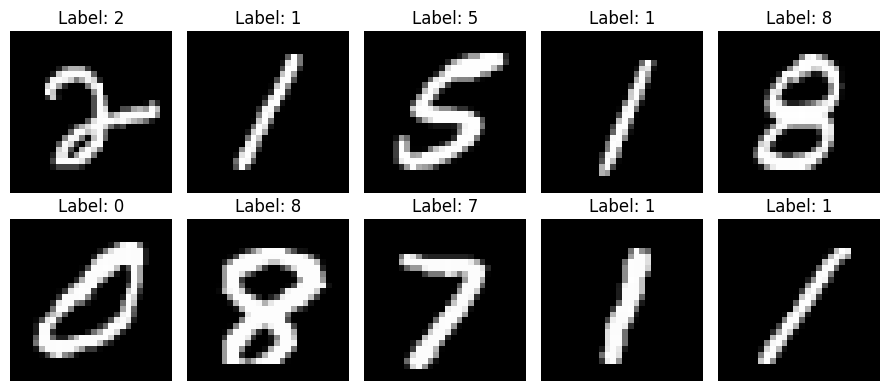

In [7]:
plt.figure(figsize=(9, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 6. Build efficient TensorFlow input pipelines

In [8]:
def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(buffer_size=min(len(images), 10000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

print("Input pipelines are ready.")


Input pipelines are ready.


## 7. Build the CNN model

In [9]:
def build_model():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))

    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D()(x)

    x = tf.keras.layers.Conv2D(96, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)

    # Keep output in float32 for numerically stable loss under mixed precision.
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
    return tf.keras.Model(inputs, outputs, name="MNIST_CNN")

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 96)       │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 96)       │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 96)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           970 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,946 (296.66 KB)

 Trainable params: 75,562 (295.16 KB)

 Non-trainable params: 384 (1.50 KB)

## 8. Train the model

In [10]:
OUTPUT_DIR = Path("/content/CodeAlpha_HandwrittenCharacterRecognition")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
best_model_path = OUTPUT_DIR / "best_mnist_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-5,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Load the best checkpoint if it was saved.
if best_model_path.exists():
    model = tf.keras.models.load_model(best_model_path)

print("Training finished. Best model:", best_model_path)


Epoch 1/12
211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.7888 - loss: 0.8272
Epoch 1: val_accuracy improved from None to 0.18550, saving model to /content/CodeAlpha_HandwrittenCharacterRecognition/best_mnist_cnn.keras

Epoch 1: finished saving model to /content/CodeAlpha_HandwrittenCharacterRecognition/best_mnist_cnn.keras
211/211 ━━━━━━━━━━━━━━━━━━━━ 36s 84ms/step - accuracy: 0.9079 - loss: 0.4194 - val_accuracy: 0.1855 - val_loss: 6.0756 - learning_rate: 0.0010
Epoch 2/12
207/211 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9763 - loss: 0.1074
Epoch 2: val_accuracy did not improve from 0.18550
211/211 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9786 - loss: 0.0924 - val_accuracy: 0.1497 - val_loss: 5.6456 - learning_rate: 0.0010
Epoch 3/12
206/211 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9858 - loss: 0.0620
Epoch 3: val_accuracy improved from 0.18550 to 0.91617, saving model to /content/CodeAlpha_HandwrittenCharacterRecognition/best_mnist_cnn.keras

Epoch 3: fini

## 9. Plot training and validation performance

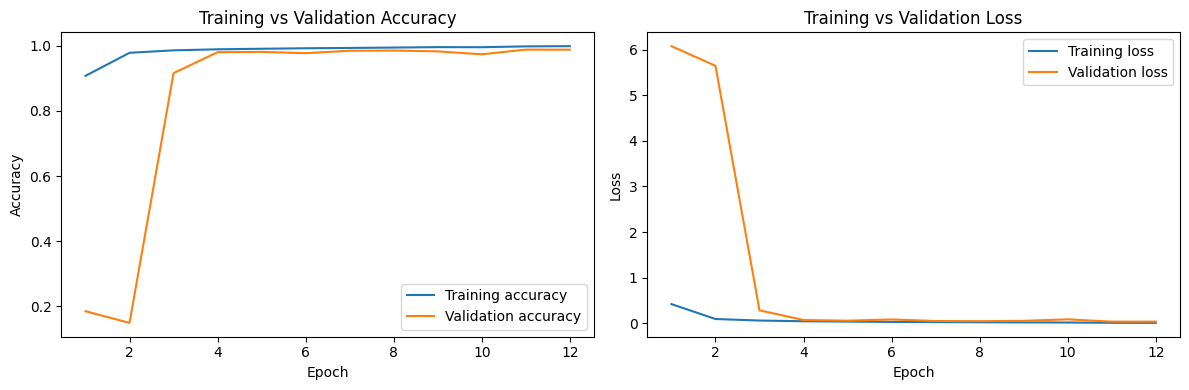

In [11]:
hist = history.history
epochs_ran = range(1, len(hist["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_ran, hist["accuracy"], label="Training accuracy")
plt.plot(epochs_ran, hist["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, hist["loss"], label="Training loss")
plt.plot(epochs_ran, hist["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()


## 10. Evaluate on the held-out test set

In [12]:
test_loss, test_keras_accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame([{
    "Test Loss": test_loss,
    "Accuracy": accuracy,
    "Precision (weighted)": precision,
    "Recall (weighted)": recall,
    "F1-score (weighted)": f1
}])
display(metrics_df.style.format("{:.4f}"))

metrics_df.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
print("\nClassification Report:\n")
report = classification_report(y_test, y_pred, digits=4, zero_division=0)
print(report)

with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(report)


,Test Loss,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,0.0273,0.9921,0.9921,0.9921,0.9921



Classification Report:

              precision    recall  f1-score   support

           0     0.9929    0.9949    0.9939       980
           1     0.9965    0.9956    0.9960      1135
           2     0.9866    0.9990    0.9928      1032
           3     0.9950    0.9941    0.9946      1010
           4     0.9888    0.9878    0.9883       982
           5     0.9922    0.9922    0.9922       892
           6     0.9958    0.9927    0.9942       958
           7     0.9980    0.9825    0.9902      1028
           8     0.9918    0.9928    0.9923       974
           9     0.9833    0.9891    0.9862      1009

    accuracy                         0.9921     10000
   macro avg     0.9921    0.9921    0.9921     10000
weighted avg     0.9921    0.9921    0.9921     10000



## 11. Confusion matrix

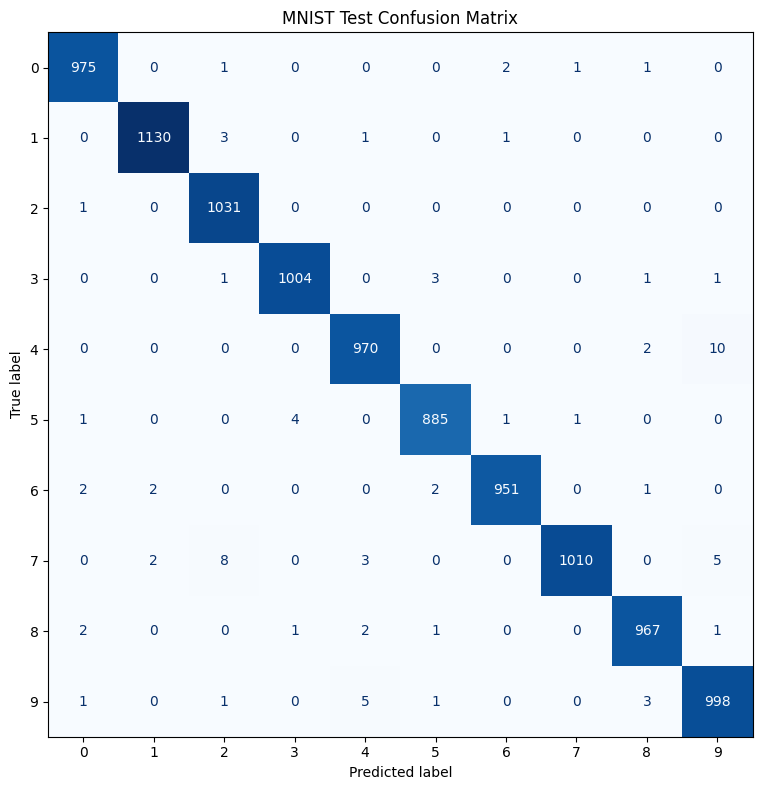

In [13]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("MNIST Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()


## 12. Inspect sample predictions

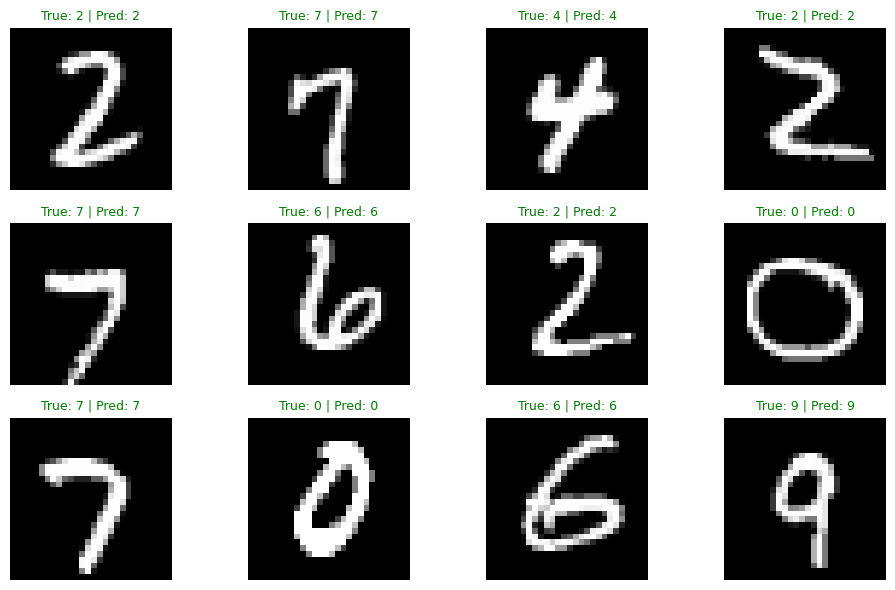

In [14]:
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test), size=12, replace=False)

plt.figure(figsize=(10, 6))
for plot_i, idx in enumerate(sample_indices, start=1):
    plt.subplot(3, 4, plot_i)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    color = "green" if y_pred[idx] == y_test[idx] else "red"
    plt.title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_predictions.png", dpi=150)
plt.show()


## 13. Save final model and project outputs

In [15]:
final_model_path = OUTPUT_DIR / "mnist_cnn_final.keras"
model.save(final_model_path)

# Save a compact record of the run configuration and final metrics.
run_info = {
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS,
    "epochs_ran": len(hist["accuracy"]),
    "image_size": IMG_SIZE,
    "model": "CNN",
    "dataset": "Kaggle: oddrationale/mnist-in-csv",
    "test_accuracy": float(accuracy),
    "test_precision_weighted": float(precision),
    "test_recall_weighted": float(recall),
    "test_f1_weighted": float(f1)
}
with open(OUTPUT_DIR / "run_summary.json", "w") as f:
    json.dump(run_info, f, indent=4)

print("Saved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, "-", f"{p.stat().st_size / (1024 * 1024):.2f} MB")


Saved files:
best_mnist_cnn.keras - 1.51 MB
classification_report.txt - 0.00 MB
confusion_matrix.png - 0.05 MB
mnist_cnn_final.keras - 1.51 MB
run_summary.json - 0.00 MB
sample_predictions.png - 0.03 MB
test_metrics.csv - 0.00 MB
training_curves.png - 0.06 MB


## 14. Download project outputs

This creates a ZIP containing the trained model, metrics, report, and plots. The notebook itself can be downloaded separately from Colab using **File → Download → Download .ipynb**.


In [16]:
import shutil

zip_path = shutil.make_archive(
    "/content/CodeAlpha_HandwrittenCharacterRecognition",
    "zip",
    root_dir=OUTPUT_DIR
)
print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)


ZIP created: /content/CodeAlpha_HandwrittenCharacterRecognition.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. GitHub submission checklist

Create a public or private GitHub repository named exactly:

`CodeAlpha_HandwrittenCharacterRecognition`

Upload:
- This notebook (`.ipynb`)
- `best_mnist_cnn.keras` or `mnist_cnn_final.keras` (model file)
- `test_metrics.csv`
- `classification_report.txt`
- `training_curves.png`
- `confusion_matrix.png`
- `sample_predictions.png`
- `run_summary.json`

**Security:** Never upload `kaggle.json`, Kaggle credentials, or any API token to GitHub.

### Short project conclusion
This project uses a Convolutional Neural Network to classify handwritten digits from the MNIST dataset. The data is normalized and reshaped into 28×28 grayscale images. The model is trained using TensorFlow/Keras and evaluated on a separate test set using accuracy, precision, recall, F1-score, a classification report, and a confusion matrix. The saved model can be reused to predict digits from new 28×28 grayscale images.
